# 02 Chemical Space Exploration, Structural Screening & Scaffold-Aware Partitioning

**Objective:** Characterize a curated set of Cyclin-Dependent Kinase 2 (CDK2) inhibitors prior to predictive modeling. The workflow implements physicochemical property profiling, structural alert screening (PAINS), molecular scaffold analysis, and a data splitting strategy designed to prevent structural data leakage.

* Drug-likeness
* Structural alerts (PAINS)
* Murcko scaffolds
* Overall chemical space

## 1. Setup and Data Load

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

 # RDKit
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Draw
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

# Statistical Modeling and Evaluation
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupShuffleSplit
from sklearn.manifold import TSNE

# Suppress RDKit warnings
RDLogger.DisableLog('rdApp.*')
sns.set_theme(style='ticks')

# Path resolution
HERE = Path.cwd()
DATA = HERE.parent / 'data'
FIGURES = HERE.parent / 'figures'
FIGURES.mkdir(exist_ok=True)


print("Done")

Done


## 2. Data Ingestion and Bioactivity Thresholding

In [2]:
# Ingest curated dataset
df = pd.read_csv(DATA / 'processed' / 'cdk2_curated.csv')

ACTIVE_THRESHOLD = 6.0

df['mol'] = df['std_smiles'].apply(Chem.MolFromSmiles)
assert df['mol'].notna().all(), 'Some SMILES failed to parse'

# Binarize categorical bioactivity outcomes
df['active'] = df['pIC50'] >= ACTIVE_THRESHOLD
df['class'] = np.where(df['active'], 'active', 'inactive')

print(len(df), "molecules: ", df['class'].value_counts().to_dict())

2044 molecules:  {'active': 1354, 'inactive': 690}


## 3. Physicochemical properties: Lipinski & Veber
* Purpose: Provides drug-likeness context for the training set
* Calculates: MW, logP (Crippen), HBD, HBA, TPSA and rotatable bonds.
* Lipinski's Rule of 5 (Ro5): Allows at most one violation of MW > 500, logP > 5, HBD > 5 or HBA > 10.
* Veber: Supplement the Ro5: Rotatable bonds (RotB) <= 10 and Topological Polar Surface Area (TPSA) <= 140

In [3]:
# Physicochemical Descriptors
def calculate_descriptors(mol):
    """
    Calculates physicochemical properties for Lipinski and Veber rules
    """
    if mol is None:
        return None
    return pd.Series({
        'MolWt': Descriptors.MolWt(mol),
        'LogP': Descriptors.MolLogP(mol),
        'HBD': Descriptors.NumHDonors(mol),
        'HBA': Descriptors.NumHAcceptors(mol),
        'TPSA': Descriptors.TPSA(mol),
        'RotB': Descriptors.NumRotatableBonds(mol),
    })
df = pd.concat([df, df['mol'].apply(calculate_descriptors)], axis=1)

df['lipinski_violations'] = (
    (df['MolWt'] > 500).astype(int) + 
    (df['LogP'] > 5).astype(int) + 
    (df['HBD'] > 5).astype(int) + 
    (df['HBA'] > 10).astype(int)
)

# Apply logical boolean flags
df['lipinski_pass'] = df['lipinski_violations'] <= 1

df['veber_pass'] = (df['RotB'] <= 10) & (df['TPSA'] <= 140)

print(f"Lipinski pass: {df['lipinski_pass'].mean():.1%} | Veber pass: {df['veber_pass'].mean():.1%}")


# Distribution summary stats
df[['MolWt', 'LogP', 'HBD', 'HBA', 'TPSA', 'RotB']].describe().round(2)

Lipinski pass: 93.4% | Veber pass: 94.5%


,MolWt,LogP,HBD,HBA,TPSA,RotB
count,2044.00,2044.00,2044.00,2044.00,2044.00,2044.00
mean,417.85,3.67,2.27,5.72,93.21,5.24
std,86.18,1.24,1.06,1.90,26.44,2.49
min,118.14,-1.09,0.00,0.00,6.48,0.00
25%,363.04,2.94,1.00,5.00,77.25,4.00
50%,418.48,3.70,2.00,6.00,92.37,5.00
75%,470.54,4.47,3.00,7.00,108.19,7.00
max,1119.78,8.65,9.00,17.00,293.55,44.00


## 4. Property Distribution Visualizations

> Active and inactive molecules have very similar property ranges. Actives are slightly more common at higher HBA and TPSA values.

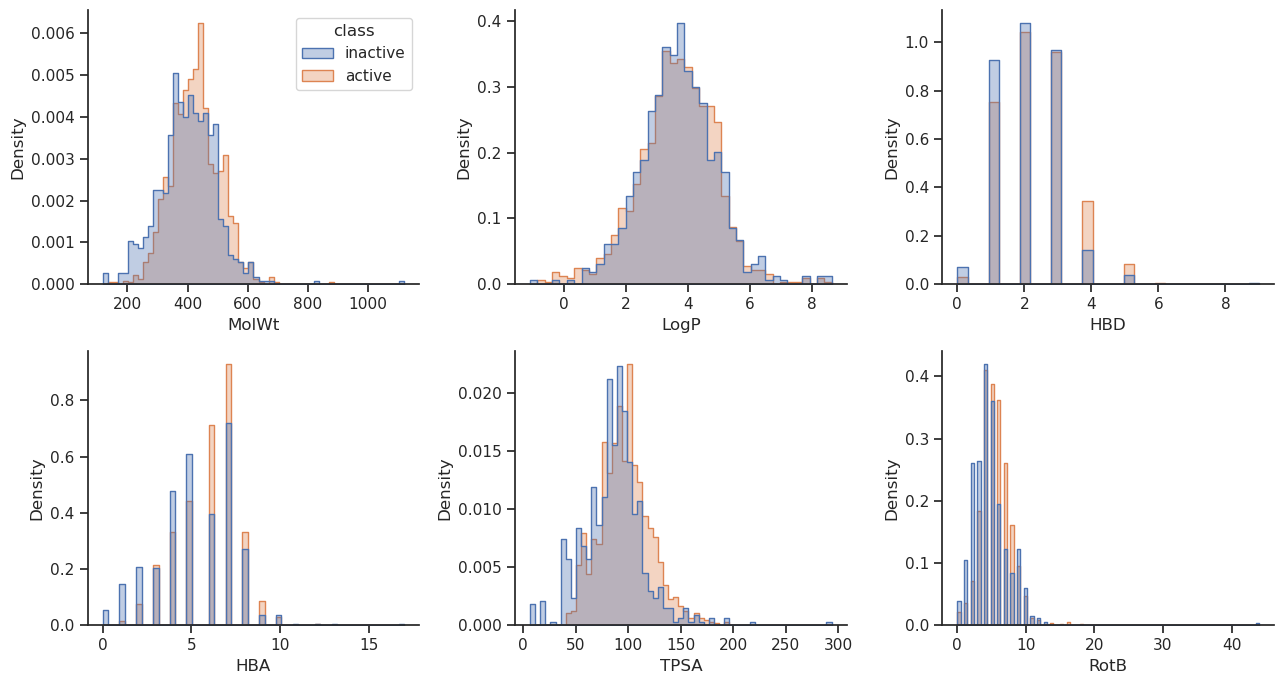

In [4]:
props = ['MolWt', 'LogP', 'HBD', 'HBA', 'TPSA', 'RotB']


fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, p in zip(axes.ravel(), props):
    sns.histplot(data=df, x=p, hue='class', stat='density', common_norm=False,
                 element='step', alpha=0.35, ax=ax)
    if ax is not axes.ravel()[0]:
        ax.get_legend().remove()

sns.despine()
plt.tight_layout()
plt.savefig(FIGURES / 'property_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Structural alert profiling (PAINS)

## PAINS
PAINS are structural patterns known to cause false positives in some lab assays. Each molecule is checked against the list and flagged. Nothing is removed.

Across all actives the flag is no more common than among inactives (7.7% vs 9.4%). Among the most potent compounds (pIC50 of 7 or higher) it is more common: 87 of 775 (11.2%), compared with 6.5% for all other compounds. Removing flagged molecules would remove some of the best actives, so they are kept.

In [5]:
# Configure and instantiate catalog with PAINS
params = FilterCatalogParams()
params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
pains_catalog = FilterCatalog(params)

def pains_hits(mol):
    return ';'.join(sorted({entry.GetDescription() for entry in pains_catalog.GetMatches(mol)})) if mol is not None else ''

df['pains'] = df['mol'].apply(pains_hits)
df['pains_flag'] = df['pains'] != ''
print(df.loc[df['pains_flag'], 'pains'].value_counts().head(10).to_markdown(), "\n")

potent = df[df['pIC50'] >= 7]
print(f"Potent (pIC50 >= 7) flagged: {potent['pains_flag'].sum()} of {len(potent)} ({potent['pains_flag'].mean():.1%})", "\n")

print(df.groupby(['pains_flag', 'class']).size().unstack(fill_value=0))

| pains                                 |   count |
|:--------------------------------------|--------:|
| azo_A(324)                            |      54 |
| anil_di_alk_A(478)                    |      35 |
| indol_3yl_alk(461)                    |      26 |
| catechol_A(92)                        |      24 |
| anil_di_alk_E(186);indol_3yl_alk(461) |       5 |
| anil_di_alk_E(186)                    |       4 |
| thio_ketone(43)                       |       4 |
| anil_di_alk_C(246)                    |       3 |
| anthranil_one_A(38);quinone_A(370)    |       3 |
| anil_no_alk(40)                       |       2 | 

Potent (pIC50 >= 7) flagged: 87 of 775 (11.2%) 

class       active  inactive
pains_flag                  
False         1250       625
True           104        65


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2044 entries, 0 to 2043
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   std_smiles           2044 non-null   str    
 1   molecule_chembl_id   2044 non-null   str    
 2   pIC50                2044 non-null   float64
 3   n_measurements       2044 non-null   int64  
 4   pIC50_range          2044 non-null   float64
 5   activity_ids         2044 non-null   str    
 6   high_variance        2044 non-null   bool   
 7   mol                  2044 non-null   object 
 8   active               2044 non-null   bool   
 9   class                2044 non-null   str    
 10  MolWt                2044 non-null   float64
 11  LogP                 2044 non-null   float64
 12  HBD                  2044 non-null   float64
 13  HBA                  2044 non-null   float64
 14  TPSA                 2044 non-null   float64
 15  RotB                 2044 non-null   float64
 16 

## 6. Molecular Framework Decomposition via Bemis-Murcko Scaffolds
### Scaffolds
Consequently, molecules sharing an identical scaffold belong to the same chemical series. In this workflow, scaffolds are employed to partition data into training and test sets. They are not utilized as model inputs.
* Stereochemistry is ignored during scaffold generation, to ensure all stereoisomers of the same molecule share the same scaffold string.

In [7]:
def murcko_scaffold(mol):
    """
    Extracts the canonical SMILES string of the Bemis-Murcko scaffold.
    """
    try:
        scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=False)
        return scaffold
    except Exception:
        return None
        
df['scaffold'] = df['mol'].apply(murcko_scaffold)
df['scaffold'].info()

<class 'pandas.Series'>
RangeIndex: 2044 entries, 0 to 2043
Series name: scaffold
Non-Null Count  Dtype
--------------  -----
2044 non-null   str  
dtypes: str(1)
memory usage: 94.3 KB


In [8]:
# Exclude anomalous or empty scaffold iterations
valid_df = df[df['scaffold'].notna() & (df['scaffold'] != '')]
scaffold_analysis = (valid_df.groupby('scaffold')
                     .agg(count=('pIC50', 'size'),
                          mean_pIC50=('pIC50', 'mean'),
                          max_pIC50=('pIC50', 'max'))
                     .sort_values('count', ascending=False))

print(scaffold_analysis.head(10))
df = valid_df.copy()

                                                    count  mean_pIC50  \
scaffold                                                                
c1cc(-c2ccc3nc[nH]c3c2)nc(Nc2ccc3c(n2)CCNC3)n1         72    7.496018   
c1ccc(Nc2ncccn2)cc1                                    67    7.929005   
c1ccc(NCCc2c[nH]c3ccccc23)cc1                          34    5.337082   
c1ccc(Nc2nccc(-c3cnc[nH]3)n2)cc1                       31    8.012980   
c1ccc(N=Nc2c[nH]c3ccccc23)cc1                          30    7.613719   
c1ccc(Nc2nccc(-c3ccccc3)n2)cc1                         28    6.580209   
c1ccc(Nc2ccnc(Nc3ccccc3)n2)cc1                         26    5.676151   
c1cc(-c2ccc3ncn(C4CC4)c3c2)nc(Nc2ccc3c(n2)CCNC3)n1     25    6.585067   
O=C1NCC2(CCCCC2)n2c1cc1cnc(Nc3ccc(N4CCNCC4)cn3)...     22    5.697578   
O=C(NC(=S)Nc1ccccc1)c1cn(-c2ccccc2)nc1-c1ccccc1        20    7.339733   

                                                    max_pIC50  
scaffold                                                   

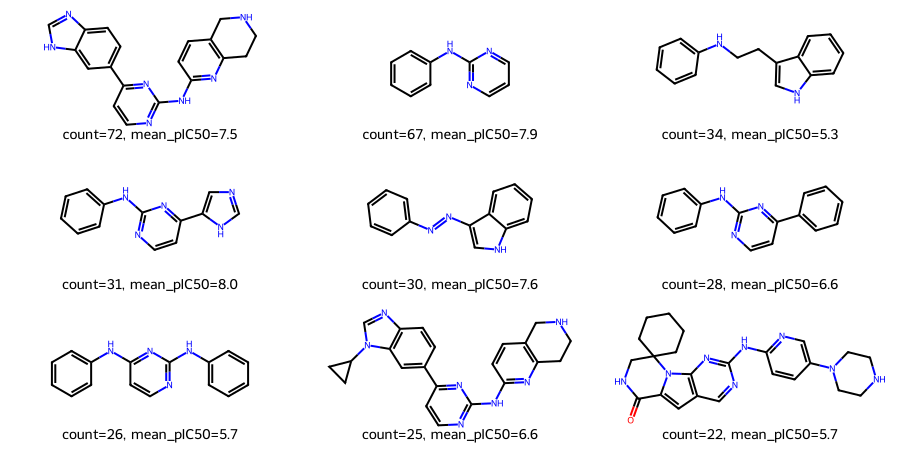

In [9]:
# Visualizing Core Chemical Series
top = scaffold_analysis.head(9)
img = Draw.MolsToGridImage(
    [ Chem.MolFromSmiles(s) for s in top.index ], molsPerRow=3, subImgSize=(300, 150),
    legends=[ f'count={i.count}, mean_pIC50={i.mean_pIC50:.1f}' for i in top.itertuples() ]
)

with open(FIGURES / 'top_scaffolds.png', 'wb') as f:
    f.write(img.data)

img

### Structural Origin of Flags
Out of 87 flagged potent compounds, 47 contain an azo alert, with 27 belong to a known PAINS class (azo-indoles), while the remainder primarily contain standard, drug-like piperazine or morpholine motifs common in kinase inhibitors.

In [10]:
potent = df[df['pIC50'] >= 7]
print(potent.loc[potent['pains_flag'], 'pains'].str.split(';').explode().value_counts().head(8))
print('')
print(potent.loc[potent['pains_flag'], 'scaffold'].value_counts().head(5))

pains
azo_A(324)            47
anil_di_alk_A(478)    22
anil_di_alk_E(186)     9
indol_3yl_alk(461)     7
thio_ketone(43)        2
catechol_A(92)         2
mannich_A(296)         1
het_65_B(7)            1
Name: count, dtype: int64

scaffold
c1ccc(N=Nc2c[nH]c3ccccc23)cc1                     27
c1cc(-c2cnc[nH]2)nc(Nc2ccc(N3CCNCC3)cc2)n1         5
c1cc(N2CCNCC2)ccc1Nc1ncc2c(n1)-c1[nH]ncc1CC2       4
O=C(Cc1ccccc1)Nc1[nH]nc2ccc(N3CCCS3(=O)=O)cc12     3
O=C(NCCc1ccc(N2CCOCC2)cc1)c1cc2ccccc2[nH]1         3
Name: count, dtype: int64


## 7. Chemical Space Visualizations using PCA & t-SNE
* Each molecule is encoded as a 2048-bit Morgan fingerprint (radius 2), where each bit marks the presence of a circular substructural environment.
* Linear and non-linear methods are used to reduce these high-dimensional vectors to two dimensions for plotting.

#### 7.1. Linear Dimensionality Reduction: Principal Component Analysis (PCA)

The sparse, binary, and high-dimensional nature of 2,048-bit Morgan Fingerprints limits effective structural relationship capturing by PCA.
Consequently, the first two principal components explain only 11.6% of the total variance, necessitating a non-linear manifold learning technique to resolve and visualize the chemical space.

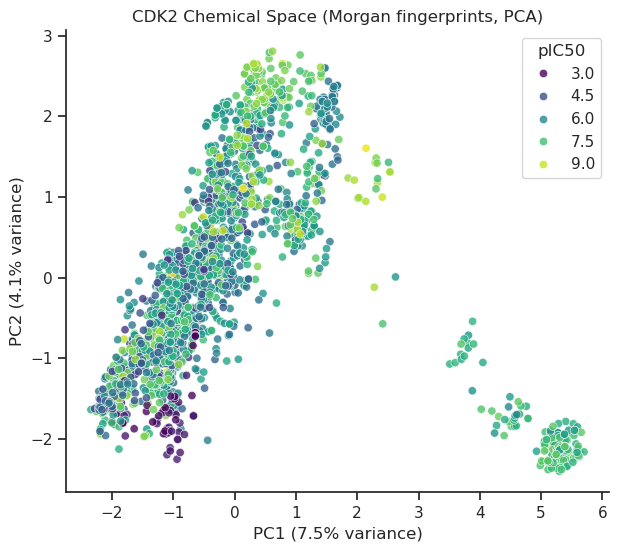

In [11]:
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X = np.array([gen.GetFingerprintAsNumPy(m) for m in df['mol']])

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)

df_vis = df[['pIC50']].copy()
df_vis['PC1'], df_vis['PC2'] = coords[:, 0], coords[:, 1]


fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(
    data=df_vis,
    x='PC1', 
    y='PC2',
    hue='pIC50',
    palette='viridis',
    alpha=0.8,
    ax=ax
)

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
ax.set_title('CDK2 Chemical Space (Morgan fingerprints, PCA)')
sns.despine()

plt.savefig(FIGURES / 'chemical_space_pca.png', dpi=300, bbox_inches='tight')
plt.show()


#### 7.2 Non-Linear Embedding: t-Distributed Stochastic Neighbor Embedding (t-SNE)

In contrast to linear methods, t-SNE preserves neighbor relationships by mapping high-dimensional similarities into low-dimensional space. This approach effectively resolves the complex molecular space into distinct, interpretable chemical clusters aligned with drug potency $pIC_{50}$.

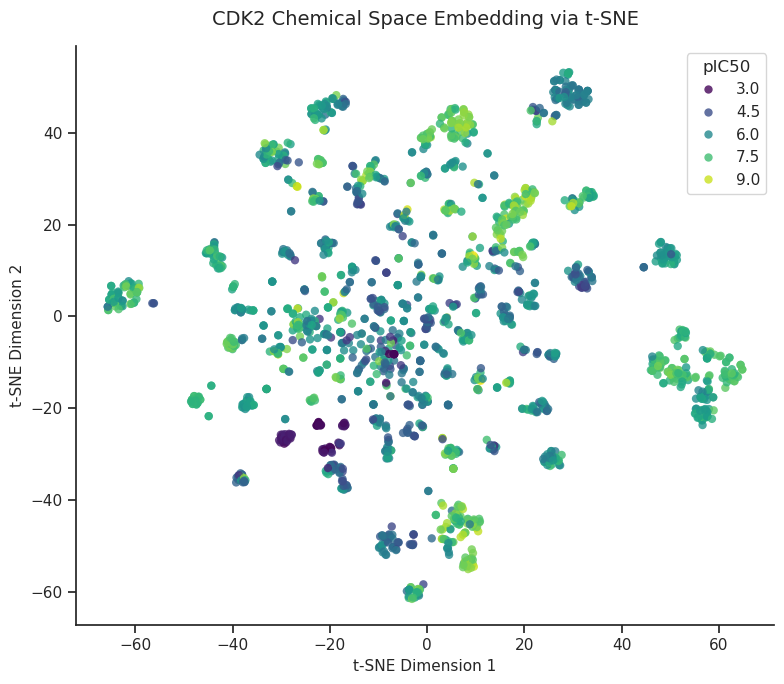

In [12]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42, max_iter=1000)
coords_tsne = tsne.fit_transform(X)

# Visualization dataframe
df_vis['TSNE1'], df_vis['TSNE2'] = coords_tsne[:, 0], coords_tsne[:, 1]

fig, ax = plt.subplots(figsize=(8, 7))
sns.scatterplot(
    data=df_vis,
    x='TSNE1',
    y='TSNE2',
    hue='pIC50',
    palette='viridis',
    alpha=0.8,
    edgecolor='none',
    ax=ax,
)

ax.set_title('CDK2 Chemical Space Embedding via t-SNE', fontsize=14, pad=15)
ax.set_xlabel('t-SNE Dimension 1', fontsize=11)
ax.set_ylabel('t-SNE Dimension 2', fontsize=11)
sns.despine()


plt.tight_layout()
plt.savefig(FIGURES / 'chemical_space_tsne.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Scaffold-based Train/Holdout Split
The dataset was partitioned to reserve 20% of the scaffold groups (17.8% of the molecules) as a holdout set. This scaffold-based split ensures the holdout contains chemical series that are unseen during training, to minimize data leakage from structural analogues.

In [13]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, holdout_idx = next(gss.split(df, groups=df['scaffold']))

df['split'] = 'train'
df.loc[df.index[holdout_idx], 'split'] = 'holdout'
train_set, holdout_set = df[df['split'] == 'train'], df[df['split'] == 'holdout']

# Checks
overlap = set(train_set['scaffold']) & set(holdout_set['scaffold'])
assert not overlap, f"{len(overlap)} scaffolds appear in both splits"
print("Split fractions:", df['split'].value_counts(normalize=True).round(3).to_dict(), "\n")

print(df.groupby('split')['class'].value_counts().unstack(fill_value=0), "\n")

print(holdout_set['scaffold'].value_counts().head())

# Save
assert not df['high_variance'].any()
df.drop(columns=['mol', 'class', 'high_variance', 'pIC50_range', 'activity_ids']).to_csv(
    DATA / 'processed' / 'cdk2_featured.csv', index=False)

Split fractions: {'train': 0.822, 'holdout': 0.178} 

class    active  inactive
split                    
holdout     202       161
train      1152       529 

scaffold
O=C1NCC2(CCCCC2)n2c1cc1cnc(Nc3ccc(N4CCNCC4)cn3)nc12    22
O=C(NC(=S)Nc1ccccc1)c1cn(-c2ccccc2)nc1-c1ccccc1        20
c1ccc(Nc2cc(Nc3ccccc3)ncn2)cc1                         16
O=C1NCC2(CCCC2)n2c1cc1cnc(Nc3ccc(N4CCNCC4)cn3)nc12     14
O=C(Nc1cc(C2CC2)[nH]n1)c1ccccc1                        13
Name: count, dtype: int64
